In [1]:
# ДЗ 4
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import deque

## Исходное изображение

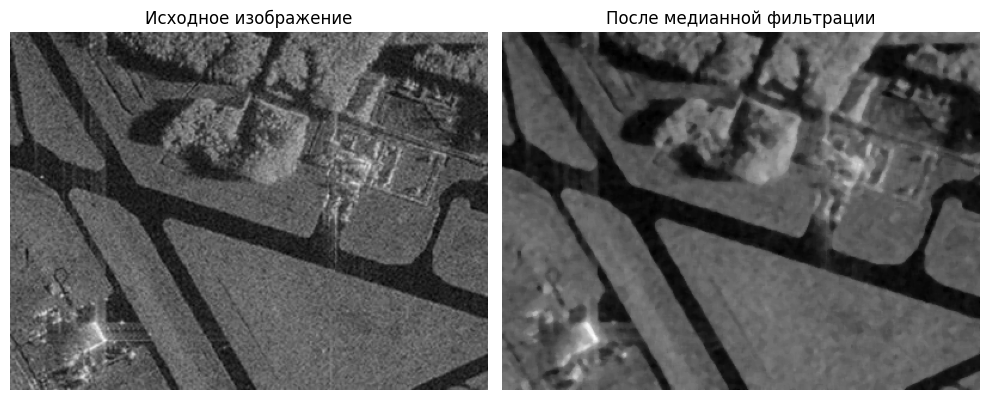

In [3]:

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

image_smooth = cv2.medianBlur(image_gray, 5)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_smooth, cmap='gray')
plt.title('После медианной фильтрации')
plt.axis('off')

plt.tight_layout()
plt.show()

## Алгоритм разрастания регионов

In [4]:
def homo_average(pixel, total, count, histogram, T):
    average = total / count
    return abs(pixel - average) <= T

def homo_median(pixel, total, count, histogram, T):
    cumulative = np.cumsum(histogram)
    low = np.searchsorted(cumulative, (count + 1) // 2)
    high = np.searchsorted(cumulative, (count + 2) // 2)
    median_value = (low + high) / 2
    return abs(pixel - median_value) <= T

def region_growing(img, seed_point, criterion, T):
    height, width = img.shape
    y0, x0 = seed_point

    if not (0 <= y0 < height and 0 <= x0 < width):
        raise ValueError('Начальная точка вне изображения')

    mask = np.zeros((height, width), dtype=np.uint8)
    mask[y0, x0] = 255
    queue = deque([(y0, x0)])
    first = int(img[y0, x0])
    histogram = np.zeros(256, dtype=np.int32)
    histogram[first] = 1
    total = first
    count = 1
    neighbours = [
        (-1, 0), (1, 0),
        (0, -1), (0, 1),
        (-1, -1), (-1, 1),
        (1, -1), (1, 1)
    ]

    while queue:
        y, x = queue.popleft()
        for dy, dx in neighbours:
            ny = y + dy
            nx = x + dx

            if (
                0 <= ny < height
                and 0 <= nx < width
                and mask[ny, nx] == 0
            ):
                value = int(img[ny, nx])

                if criterion(value, total, count, histogram, T):
                    mask[ny, nx] = 255
                    queue.append((ny, nx))
                    histogram[value] += 1
                    total += value
                    count += 1

    return mask

## Подбор параметров разрастания регионов

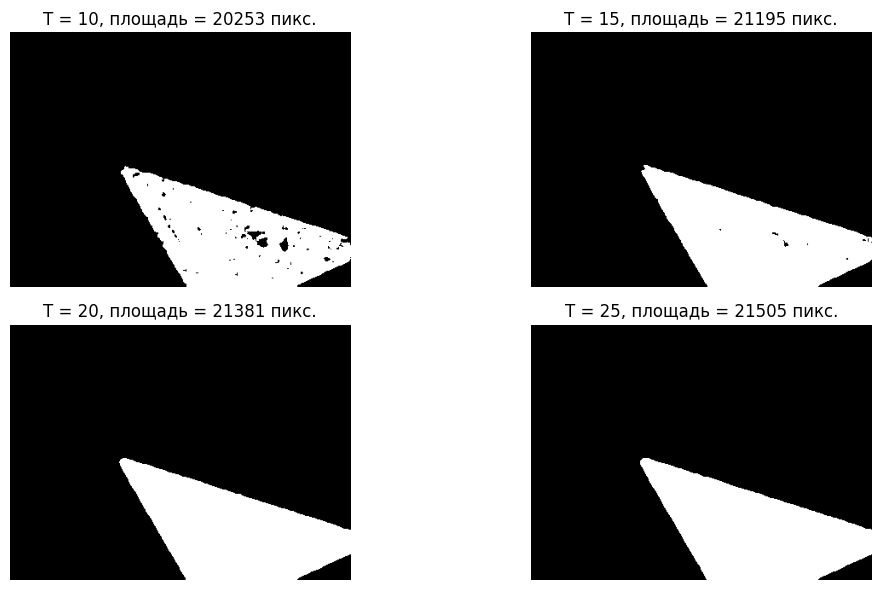

In [5]:
seed_point = (250, 250)
thresholds = [10, 15, 20, 25]
masks_t = [
    region_growing(image_smooth, seed_point, homo_average, T)
    for T in thresholds
]
plt.figure(figsize=(12, 6))
for i, (T, current_mask) in enumerate( zip(thresholds, masks_t)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(current_mask, cmap='gray', vmin=0, vmax=255)
    area = np.count_nonzero(current_mask)
    plt.title(f'T = {T}, площадь = {area} пикс.')
    plt.axis('off')

plt.tight_layout()
plt.show()

## Сравнение критериев однородности

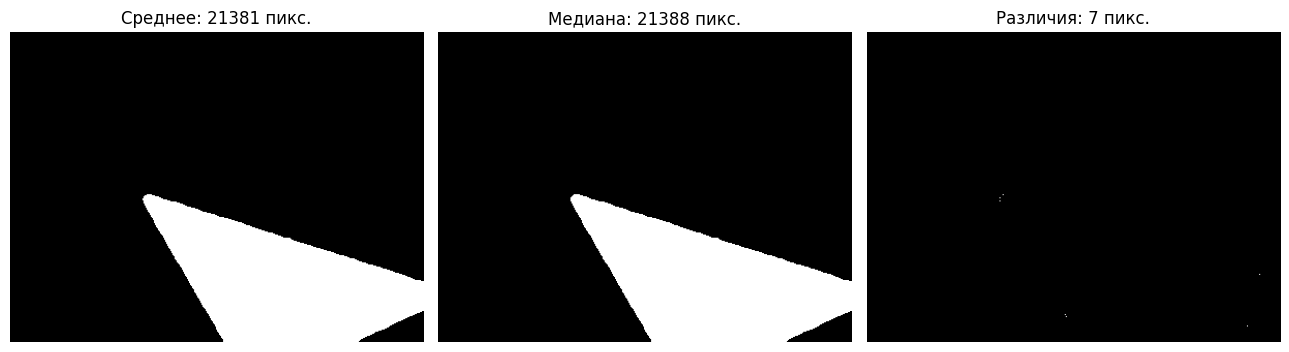

In [6]:
T = 20
mask_average = region_growing(image_smooth, seed_point, homo_average, T)
mask_median = region_growing(image_smooth, seed_point, homo_median, T)

mask_difference = cv2.absdiff(mask_average, mask_median)

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask_average, cmap='gray', vmin=0, vmax=255)
plt.title(f'Среднее: {np.count_nonzero(mask_average)} пикс.')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_median, cmap='gray', vmin=0, vmax=255)
plt.title(f'Медиана: {np.count_nonzero(mask_median)} пикс.')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_difference, cmap='gray', vmin=0, vmax=255)
plt.title(f'Различия: {np.count_nonzero(mask_difference)} пикс.')
plt.axis('off')

plt.tight_layout()
plt.show()

## Watershed + Distance Transform

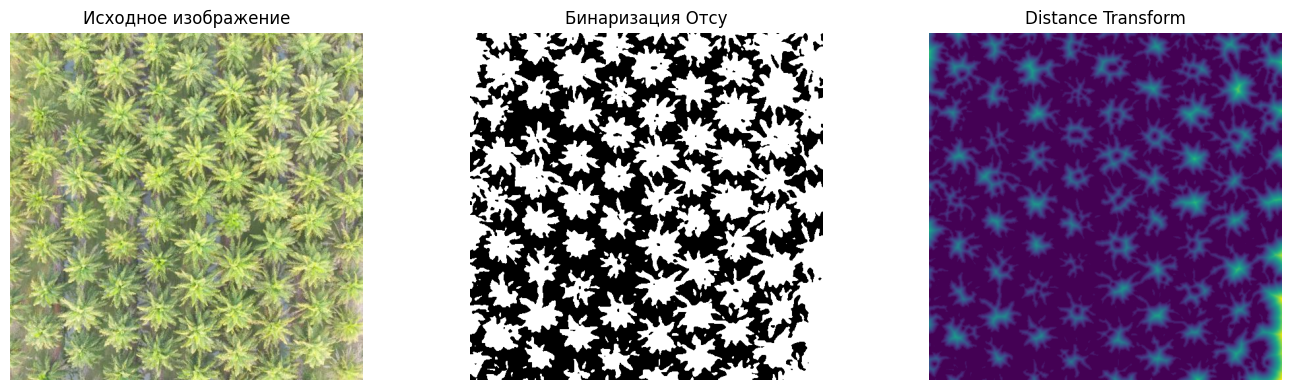

In [7]:
palm_image = cv2.imread('palm_1.JPG')
palm_rgb = cv2.cvtColor(palm_image, cv2.COLOR_BGR2RGB)
palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)
palm_smooth = cv2.GaussianBlur(palm_gray, (9, 9), 0)

_, binary = cv2.threshold(palm_smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
distance = cv2.distanceTransform(binary, cv2.DIST_L2, 5)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(palm_rgb)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(binary, cmap='gray')
plt.title('Бинаризация Отсу')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(distance, cmap='viridis')
plt.title('Distance Transform')
plt.axis('off')

plt.tight_layout()
plt.show()

## Сегментация Watershed и подсчёт пальм

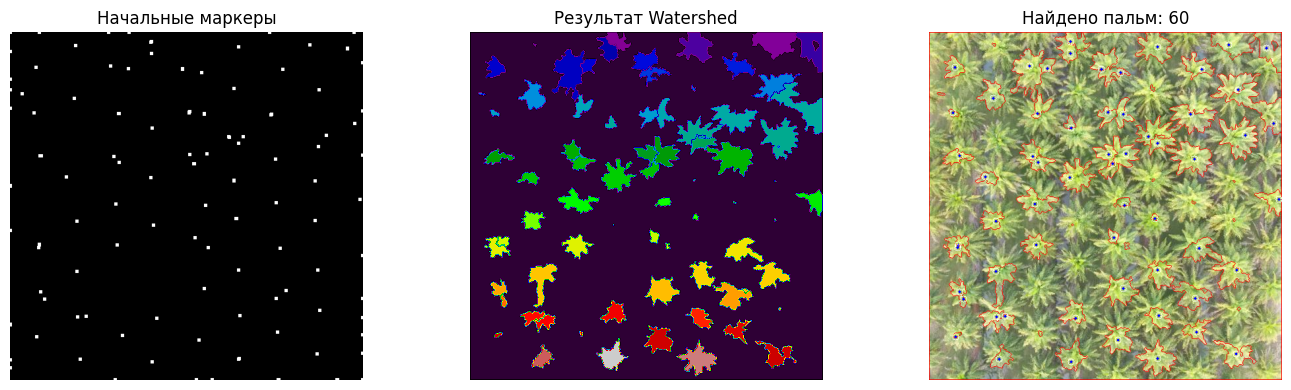

In [8]:
window_size = 21
min_distance_level = 0.30

footprint = cv2.getStructuringElement( cv2.MORPH_ELLIPSE, (window_size, window_size))
local_max = cv2.dilate(distance, footprint)
peak_mask = np.uint8((distance >= local_max - 1e-6) & (distance > min_distance_level * distance.max()))

num_labels, seed_labels, stats, centers = (cv2.connectedComponentsWithStats(peak_mask, connectivity=8))

sure_background = cv2.dilate(binary, np.ones((3, 3), np.uint8), iterations=3)

markers = np.zeros(palm_gray.shape, dtype=np.int32)
markers[sure_background == 0] = 1
markers[seed_labels > 0] = (seed_labels[seed_labels > 0] + 1)

watershed_result = cv2.watershed(palm_image.copy(), markers)
labels, areas = np.unique(watershed_result, return_counts=True)
min_area = 50
palm_labels = [
    int(label)
    for label, area in zip(labels, areas)
    if label > 1 and area >= min_area
]
palm_count = len(palm_labels)

result_rgb = palm_rgb.copy()
result_rgb[watershed_result == -1] = (255, 0, 0)
for label in palm_labels:
    x, y = np.round(centers[label - 1]).astype(int)

    cv2.circle(result_rgb, (x, y), 5, (255, 255, 255), 1)
    cv2.circle(result_rgb, (x, y), 2, (0, 0, 255), -1)


markers_view = cv2.dilate(peak_mask * 255, np.ones((5, 5), np.uint8))

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(markers_view, cmap='gray')
plt.title('Начальные маркеры')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(watershed_result, cmap='nipy_spectral')
plt.title('Результат Watershed')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(result_rgb)
plt.title(f'Найдено пальм: {palm_count}')
plt.axis('off')

plt.tight_layout()
plt.show()